In [53]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

In [54]:
def display_images(images, columns=2, figsize=(8, 10)):
    rows = (len(images) + columns - 1) // columns
    plt.figure(figsize=figsize)

    for i, (title, image) in enumerate(images.items(), start=1):
        plt.subplot(rows, columns, i)
        plt.imshow(image, cmap="gray")
        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

### Binary image

The 15 x 15 matrix contains one solid rectangle. Values are 0 for background and 1 for foreground, stored as `np.uint8`.

In [55]:
binary = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
], dtype=np.uint8)

### Kernels and settings

Choose `kernelName` from `rect`, `cross`, `ellipse`, `diagonal`, or `antiDiagonal`. OpenCV supplies the first three; NumPy creates the diagonals.

`kernelSizes` contains (width, height) pairs. `sizeKernels` stores the chosen shape at each size, and `kernel` selects the first size. `iterations` controls the erosion and dilation comparisons.

The `hitmiss` entry is a separate, fixed 3 x 3 signed pattern: 1 requires foreground, -1 requires background, and 0 ignores that position. It is used only for hit-or-miss.

In [56]:
kernelName = "cross"
kernelSizes = [(3, 3), (5, 5), (7, 7)]
iterations = range(1, 4)
sizeKernels = {}

for kernelSize in kernelSizes:
    width, height = kernelSize

    kernels = {
        "rect": cv.getStructuringElement(cv.MORPH_RECT, kernelSize),
        "cross": cv.getStructuringElement(cv.MORPH_CROSS, kernelSize),
        "ellipse": cv.getStructuringElement(cv.MORPH_ELLIPSE, kernelSize),
        "diagonal": np.eye(height, width, dtype=np.uint8),
        "antiDiagonal": np.fliplr(np.eye(height, width, dtype=np.uint8)).copy(),
        "hitmiss": np.array([[-1, -1, -1], [0, 1, 0], [1, 1, 1]], dtype=np.int8)
    }

    sizeKernels[kernelSize] = kernels[kernelName]

kernel = sizeKernels[kernelSizes[0]]

### 1. Erosion

Erosion shrinks foreground regions by keeping pixels only where the kernel fits. Each loop iteration starts from the original image.

**Inference:** Increasing the iteration count removes more foreground. Small objects may disappear.

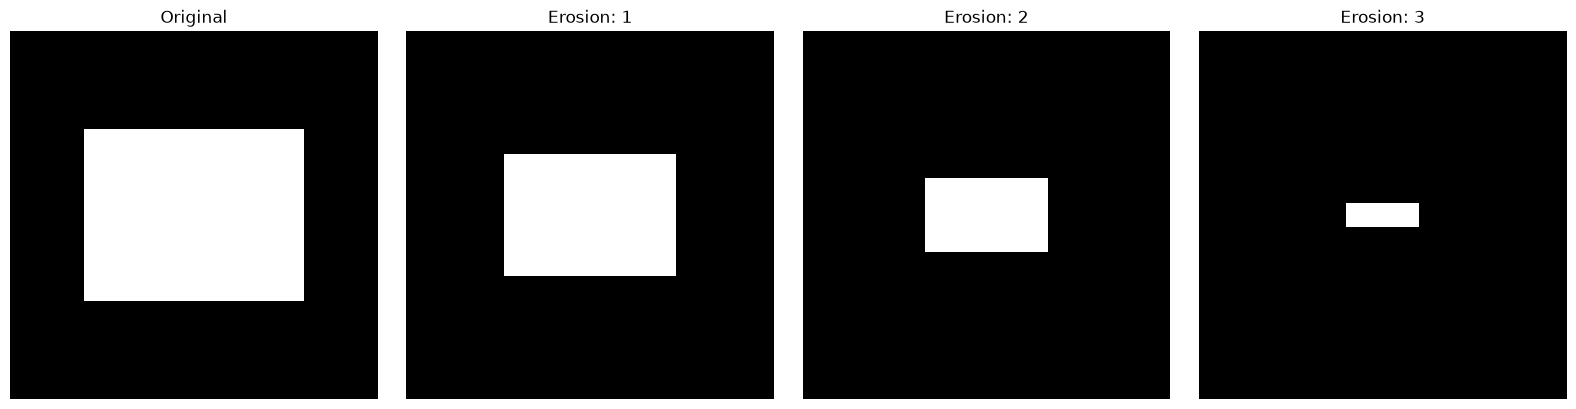

In [57]:
images = {"Original": binary}

for iteration in iterations:
    eroded = cv.erode(binary, kernel, iterations=iteration)
    images[f"Erosion: {iteration}"] = eroded

display_images(images, columns=4, figsize=(16, 4))

### 2. Dilation

Dilation expands foreground regions according to the kernel. Each loop iteration starts from the original image.

**Inference:** More iterations enlarge objects and may join nearby regions.

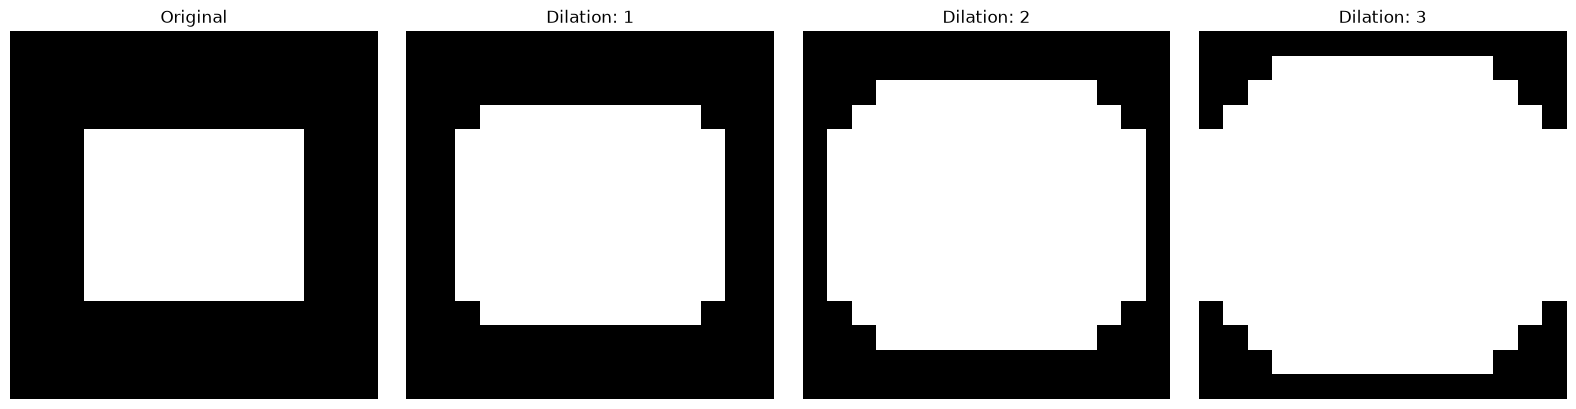

In [58]:
images = {"Original": binary}

for iteration in iterations:
    dilated = cv.dilate(binary, kernel, iterations=iteration)
    images[f"Dilation: {iteration}"] = dilated

display_images(images, columns=4, figsize=(16, 4))

### 3. Opening

Opening applies erosion followed by dilation using the same kernel. The loop compares the selected shape at different sizes.

**Inference:** Opening removes small foreground details. A kernel larger than an object can remove the object completely.

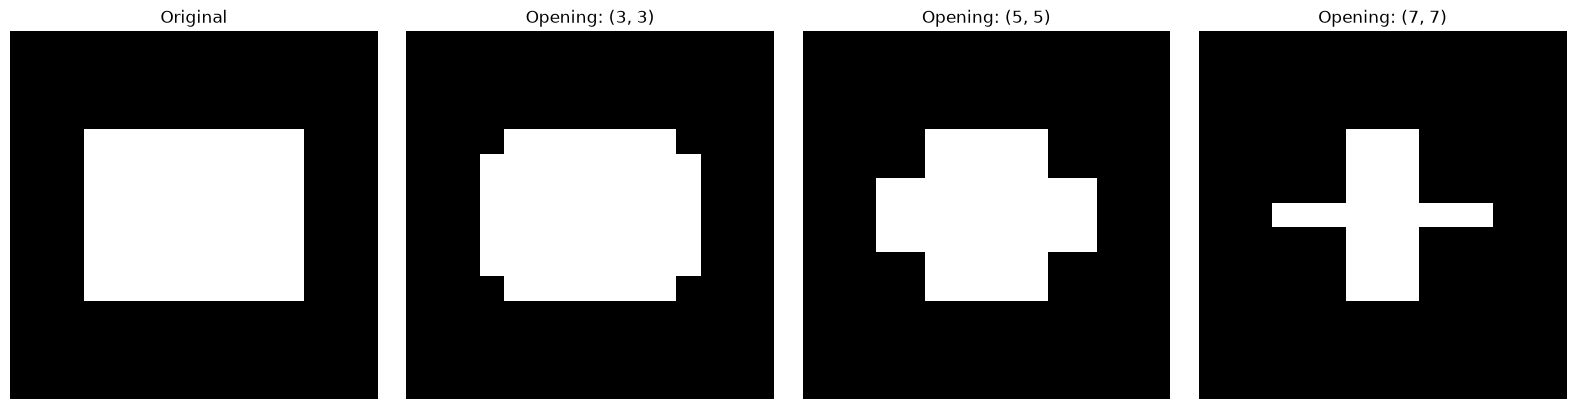

In [59]:
images = {"Original": binary}

for kernelSize, sizeKernel in sizeKernels.items():
    opening = cv.morphologyEx(binary, cv.MORPH_OPEN, sizeKernel)
    images[f"Opening: {kernelSize}"] = opening

display_images(images, columns=4, figsize=(16, 4))

### 4. Closing

Closing applies dilation followed by erosion using the same kernel. The loop compares the selected shape at different sizes.

**Inference:** The solid rectangle has no holes or gaps to fill. Closing may still affect corners depending on the kernel.

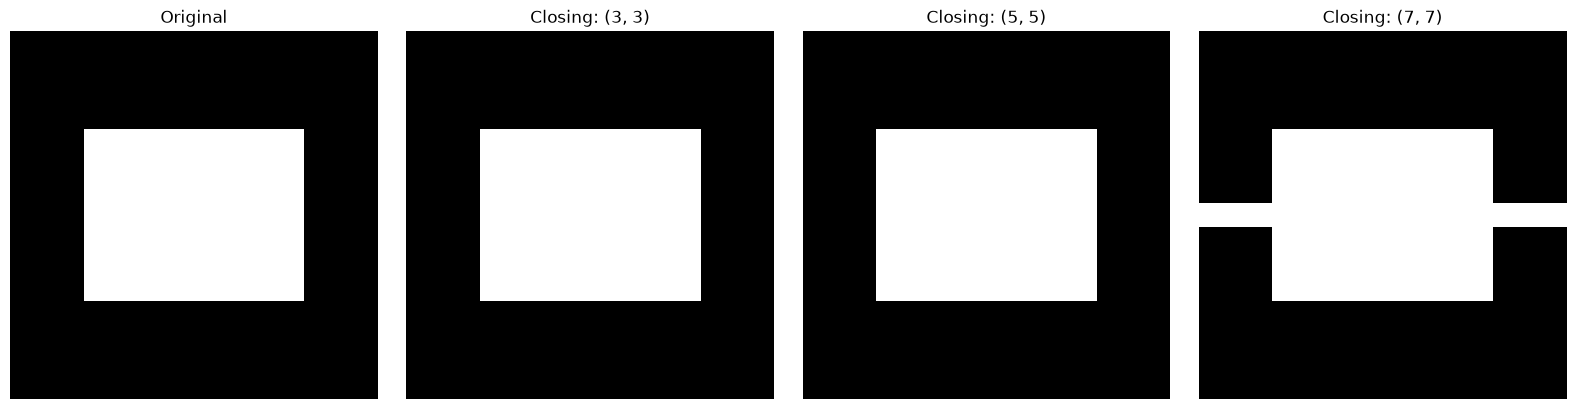

In [60]:
images = {"Original": binary}

for kernelSize, sizeKernel in sizeKernels.items():
    closing = cv.morphologyEx(binary, cv.MORPH_CLOSE, sizeKernel)
    images[f"Closing: {kernelSize}"] = closing

display_images(images, columns=4, figsize=(16, 4))

### 5. Hit-or-miss

Hit-or-miss finds locations matching both foreground and background requirements. The dictionary pattern looks for the middle of a top horizontal edge: background above, foreground at the center, and three foreground pixels below.

**Inference:** Matching pixels mark top horizontal edges with the required background above and foreground below. Several locations can match this pattern.

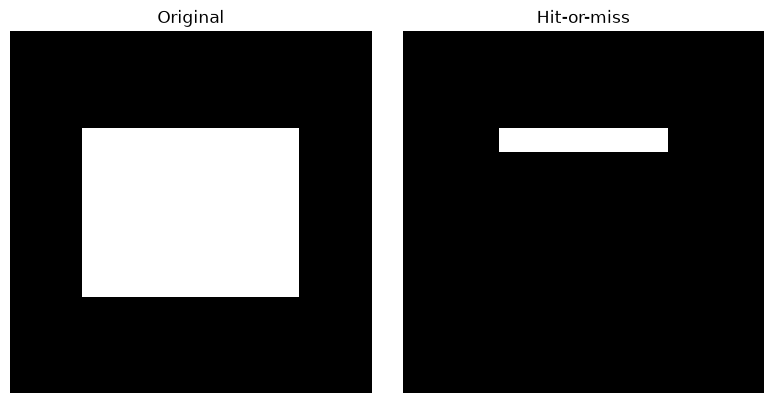

In [61]:
hitmissKernel = kernels["hitmiss"]
hitmiss = cv.morphologyEx(binary, cv.MORPH_HITMISS, hitmissKernel)

display_images({"Original": binary, "Hit-or-miss": hitmiss}, columns=2, figsize=(8, 4))

### 6. Boundary detection

The inner boundary is the original minus its erosion. The outer boundary is the dilation minus the original.

**Inference:** The inner outline lies inside the object, while the outer outline lies outside it. The kernel controls their shape and thickness.

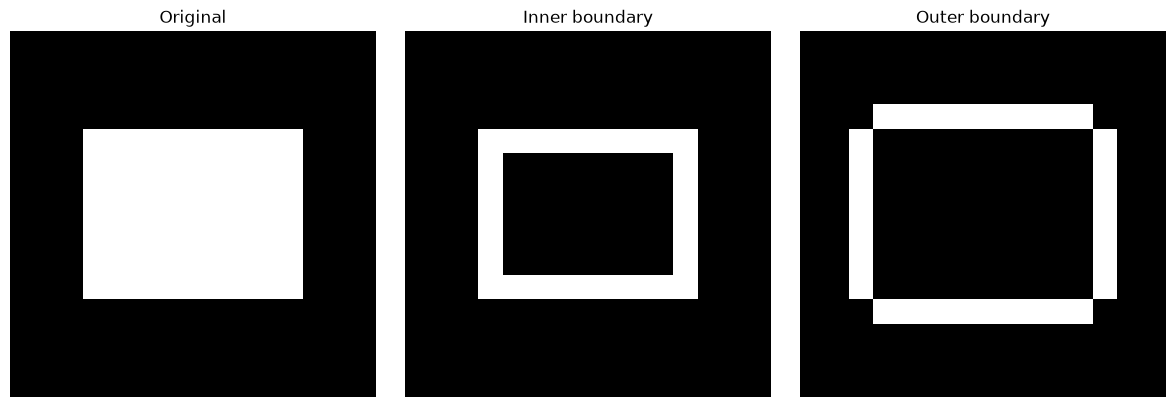

In [62]:
eroded = cv.erode(binary, kernel)
dilated = cv.dilate(binary, kernel)

innerBoundary = cv.subtract(binary, eroded)
outerBoundary = cv.subtract(dilated, binary)

display_images({"Original": binary, "Inner boundary": innerBoundary, "Outer boundary": outerBoundary}, columns=3, figsize=(12, 4))

### 7. Region filling

Find external contours and draw their interiors as foreground. This fills holes enclosed by each outer contour.

**Inference:** The rectangle is already solid, so filling leaves it unchanged. The contours are reused for the convex hull.

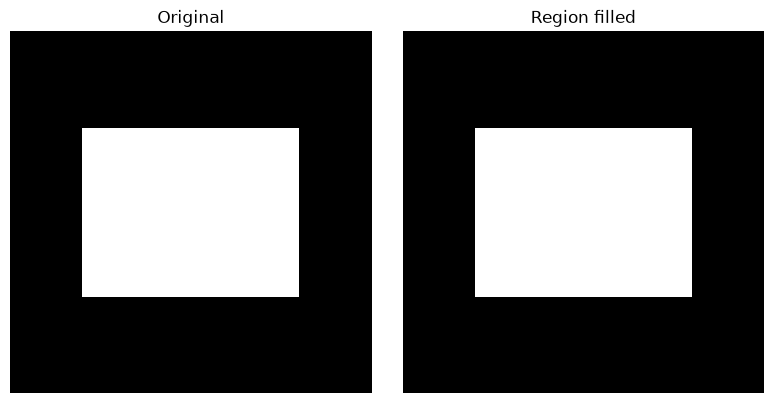

In [63]:
contours, _ = cv.findContours(binary, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
filled = np.zeros_like(binary)

cv.drawContours(filled, contours, -1, 1, cv.FILLED)

display_images({"Original": binary, "Region filled": filled}, columns=2, figsize=(8, 4))

### 8. Convex hull

For each contour, find and fill the smallest convex shape enclosing it.

**Inference:** The rectangle is already convex, so its hull is unchanged.

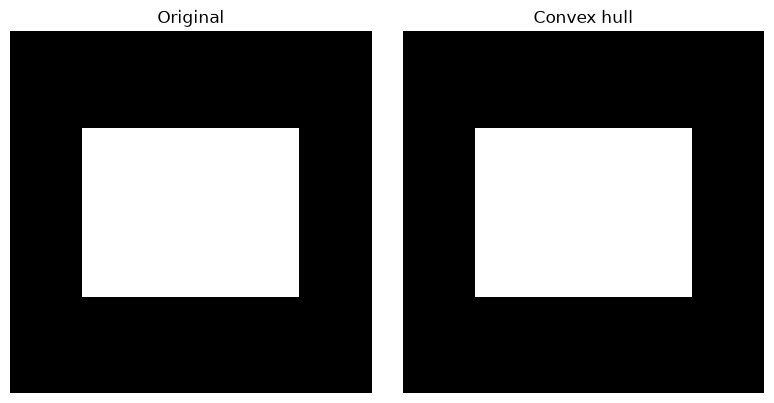

In [64]:
convexHullImage = np.zeros_like(binary)

for contour in contours:
    hull = cv.convexHull(contour)
    cv.drawContours(convexHullImage, [hull], -1, 1, cv.FILLED)

display_images({"Original": binary, "Convex hull": convexHullImage}, columns=2, figsize=(8, 4))

### 9. Thinning

Thinning reduces foreground regions toward a one-pixel-wide skeleton while preserving connectivity. OpenCV requires `ximgproc.thinning`, available in `opencv-contrib-python`, and foreground values of 255.

**Inference:** The result keeps the basic structure while removing thickness. If the function is unavailable, the cell prints the required package name.

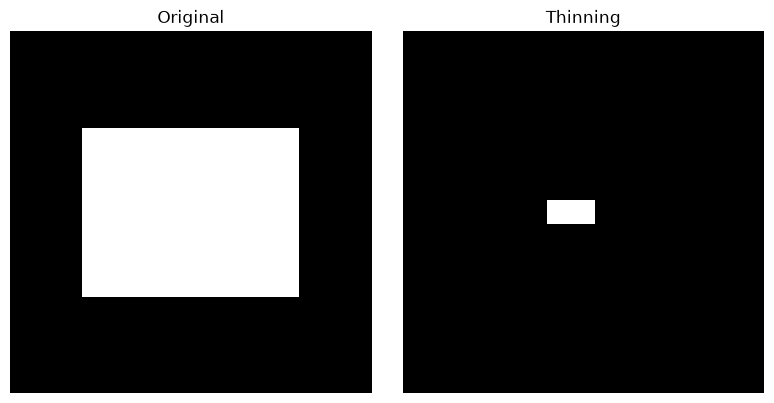

In [65]:
if hasattr(cv, "ximgproc") and hasattr(cv.ximgproc, "thinning"):
    thinning = cv.ximgproc.thinning(binary * 255)
    display_images({"Original": binary, "Thinning": thinning}, columns=2, figsize=(8, 4))
else:
    print("Thinning requires opencv-contrib-python.")

### 10. Thickening approximation

Dilation is used here as a simple way to increase foreground thickness.

**Inference:** This produces the same result as one dilation. Formal morphological thickening instead adds pixels using hit-or-miss patterns.

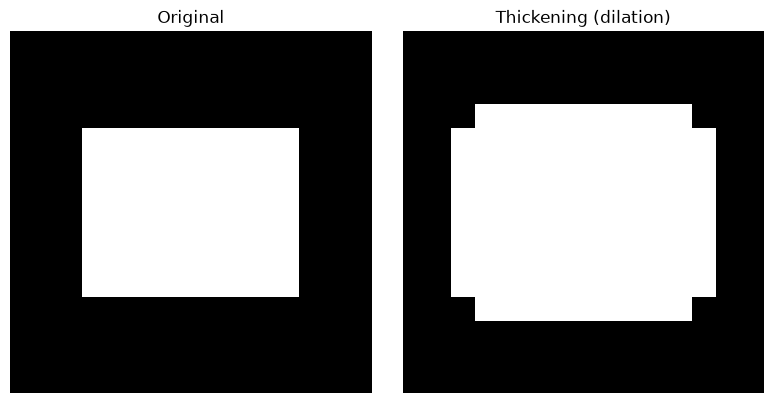

In [66]:
thickening = cv.dilate(binary, kernel)

display_images({"Original": binary, "Thickening (dilation)": thickening}, columns=2, figsize=(8, 4))

### 11. Watershed segmentation

Opening cleans the binary image. Dilation estimates the object and its surrounding area; the distance transform selects sure foreground pixels away from edges. Their difference gives the unknown region.

Connected components label the foreground seeds. Marker 1 represents background, and marker 0 represents unknown pixels. Watershed grows the labeled regions and marks boundaries with -1, which are displayed in red.

**Inference:** The rectangle provides one foreground region. Separating touching objects would require distinct foreground seeds.

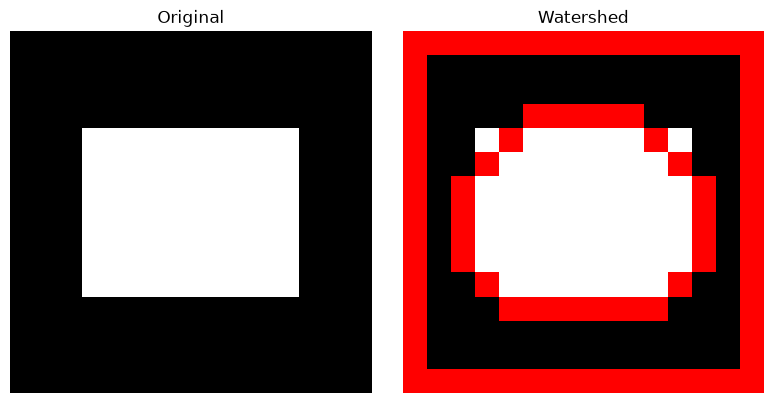

In [67]:
watershedBinary = binary * 255
watershedOpening = cv.morphologyEx(watershedBinary, cv.MORPH_OPEN, kernel)
sureBackground = cv.dilate(watershedOpening, kernel, iterations=3)

distance = cv.distanceTransform(watershedOpening, cv.DIST_L2, 5)
sureForeground = np.uint8(distance > 0.5 * distance.max()) * 255
unknown = cv.subtract(sureBackground, sureForeground)

_, markers = cv.connectedComponents(sureForeground)
markers += 1
markers[unknown == 255] = 0

watershedImage = cv.cvtColor(watershedBinary, cv.COLOR_GRAY2RGB)
markers = cv.watershed(watershedImage, markers)
watershedImage[markers == -1] = [255, 0, 0]

display_images({"Original": binary, "Watershed": watershedImage}, columns=2, figsize=(8, 4))